# Credit card fraud detection: imbalanced data, cost-based threshold and SHAP

**Objective:** build a fraud detection model like a payments or bank risk team would do it: with a split by **time** (we train with the past and test with the future, not a random split), metrics for very imbalanced data (precision-recall), a decision threshold chosen with the **cost** of each error, and explanations of the alerts with SHAP.

**Data:** "Credit Card Fraud Detection" (ULB Machine Learning Group, Worldline), OpenML dataset 1597: 284.807 card transactions of two days in September 2013, 492 frauds (0.17%). Variables V1 to V28 are PCA components (anonymised), plus `Amount`. The OpenML version does not have the column `Time`, but the rows are in chronological order, so we use the position of the row as the clock.

Libraries of the project: `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `lightgbm` and `shap`.

## Part 1. Libraries and data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
import lightgbm as lgb
import shap

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

C:\Users\lezqu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
ruta = "data/creditcard.parquet"
if not os.path.exists(ruta):
    d = fetch_openml(data_id=1597, as_frame=True, parser="auto")
    df = d.frame
    df["Class"] = df["Class"].astype(int)
    df.to_parquet(ruta)
df = pd.read_parquet(ruta)
print("Transactions:", len(df), "| frauds:", df["Class"].sum(), "| fraud rate:", round(df["Class"].mean() * 100, 3), "%")
df.head()

Transactions: 284807 | frauds: 492 | fraud rate: 0.173 %


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Part 2. Exploration

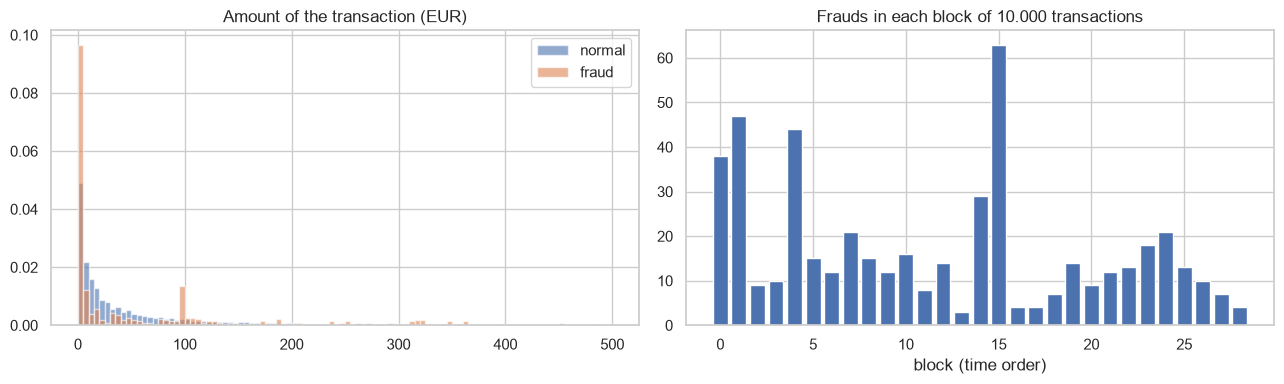

Median amount normal: 22.0 | fraud: 9.25


In [3]:
df["orden"] = np.arange(len(df))          # position of the transaction in time
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df.loc[df["Class"] == 0, "Amount"], bins=100, range=(0, 500), alpha=0.6, density=True, label="normal")
axes[0].hist(df.loc[df["Class"] == 1, "Amount"], bins=100, range=(0, 500), alpha=0.6, density=True, label="fraud")
axes[0].set_title("Amount of the transaction (EUR)")
axes[0].legend()
bloques = df.groupby(df["orden"] // 10000)["Class"].sum()
axes[1].bar(bloques.index, bloques.values)
axes[1].set_title("Frauds in each block of 10.000 transactions")
axes[1].set_xlabel("block (time order)")
plt.tight_layout()
plt.show()
print("Median amount normal:", df.loc[df["Class"] == 0, "Amount"].median(), "| fraud:", df.loc[df["Class"] == 1, "Amount"].median())

The median fraud is smaller than the median normal transaction, but the distribution has a long tail. Frauds are not uniform in time either: some blocks have many more frauds than others (attacks come in waves).

## Part 3. Split by time

A random split would mix the same fraud attacks in train and test and give optimistic results. We train with the first 70% of the time and test with the last 30%.

In [4]:
df["log_amount"] = np.log1p(df["Amount"])
x_cols = [f"V{i}" for i in range(1, 29)] + ["log_amount"]
corte = df["orden"].quantile(0.7)
train, test = df[df["orden"] <= corte], df[df["orden"] > corte]
x_train, y_train = train[x_cols], train["Class"]
x_test, y_test = test[x_cols], test["Class"]
print("Train:", len(train), "frauds", y_train.sum(), "| Test:", len(test), "frauds", y_test.sum())

Train: 199365 frauds 384 | Test: 85442 frauds 108


## Part 4. Models

With 0.17% of frauds the ROC-AUC is always high, so the main metric is the **average precision** (area under the precision-recall curve).

In [5]:
logit = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))
logit.fit(x_train, y_train)
p_logit = logit.predict_proba(x_test)[:, 1]

gbm = lgb.LGBMClassifier(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=50,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8, scale_pos_weight=5, verbose=-1, random_state=42)
gbm.fit(x_train, y_train)
p_gbm = gbm.predict_proba(x_test)[:, 1]

resultados = pd.DataFrame({
    "ROC-AUC": [roc_auc_score(y_test, p_logit), roc_auc_score(y_test, p_gbm)],
    "Average precision": [average_precision_score(y_test, p_logit), average_precision_score(y_test, p_gbm)],
}, index=["Logistic regression", "LightGBM"])
print("Average precision of a random model:", round(y_test.mean(), 4))
resultados.round(3)

Average precision of a random model: 0.0013


,ROC-AUC,Average precision
Logistic regression,0.979,0.749
LightGBM,0.980,0.799


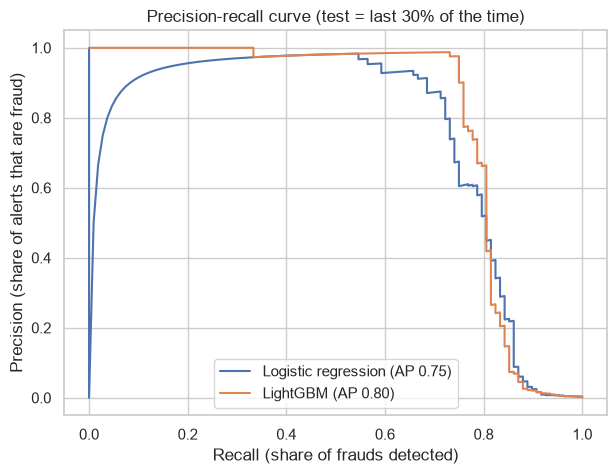

In [6]:
plt.figure(figsize=(7, 5))
for nombre, p in [("Logistic regression", p_logit), ("LightGBM", p_gbm)]:
    pr, rc, _ = precision_recall_curve(y_test, p)
    plt.plot(rc, pr, label=f"{nombre} (AP {average_precision_score(y_test, p):.2f})")
plt.title("Precision-recall curve (test = last 30% of the time)")
plt.xlabel("Recall (share of frauds detected)")
plt.ylabel("Precision (share of alerts that are fraud)")
plt.legend()
plt.savefig("figures/precision_recall.png", bbox_inches="tight")
plt.show()

## Part 5. Threshold chosen by cost

The default threshold of 0.5 has no business meaning. We assume:
- a fraud that we do not detect costs its **amount** (the bank refunds the client)
- every alert costs **5 EUR** of manual review, and a false alert also annoys a good client

and we choose the threshold that minimises the total cost in test.

Cost without model (all frauds pass): 14567 EUR
Best threshold: 0.02 | total cost: 3418 EUR | alerts: 111 | frauds caught: 84 of 108
Cost at threshold 0.5: 3556 EUR


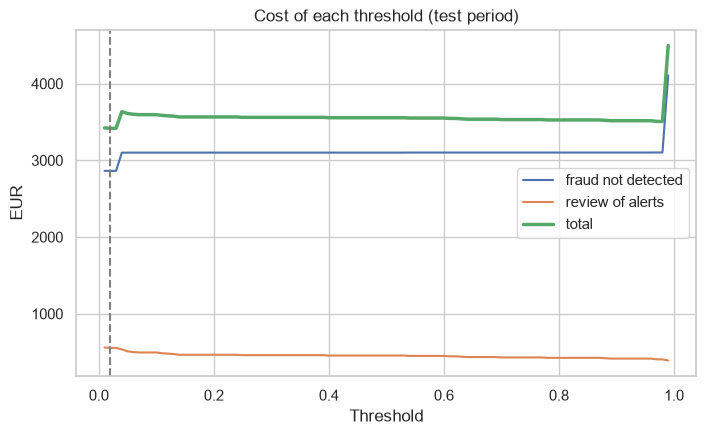

In [7]:
costo_revision = 5
montos = test["Amount"].values
umbrales = np.linspace(0.01, 0.99, 99)
filas = []
for u in umbrales:
    alerta = p_gbm >= u
    perdida = montos[(~alerta) & (y_test.values == 1)].sum()
    revision = alerta.sum() * costo_revision
    filas.append([u, perdida, revision, perdida + revision, alerta.sum(), (alerta & (y_test.values == 1)).sum()])
costos = pd.DataFrame(filas, columns=["threshold", "fraud_loss", "review_cost", "total_cost", "alerts", "frauds_caught"])
mejor = costos.loc[costos["total_cost"].idxmin()]
sin_modelo = montos[y_test.values == 1].sum()
print("Cost without model (all frauds pass):", round(sin_modelo), "EUR")
print("Best threshold:", round(mejor["threshold"], 2), "| total cost:", round(mejor["total_cost"]), "EUR | alerts:", int(mejor["alerts"]),
      "| frauds caught:", int(mejor["frauds_caught"]), "of", int(y_test.sum()))
print("Cost at threshold 0.5:", round(costos.iloc[(costos["threshold"] - 0.5).abs().idxmin()]["total_cost"]), "EUR")

plt.figure(figsize=(8, 4.5))
plt.plot(costos["threshold"], costos["fraud_loss"], label="fraud not detected")
plt.plot(costos["threshold"], costos["review_cost"], label="review of alerts")
plt.plot(costos["threshold"], costos["total_cost"], lw=2.5, label="total")
plt.axvline(mejor["threshold"], color="grey", ls="--")
plt.title("Cost of each threshold (test period)")
plt.xlabel("Threshold")
plt.ylabel("EUR")
plt.legend()
plt.savefig("figures/cost_threshold.png", bbox_inches="tight")
plt.show()

## Part 6. Why does the model raise an alert? SHAP

SHAP gives the contribution of each variable to each prediction. This is what an analyst needs to review an alert, and what model risk asks to accept a black-box model.

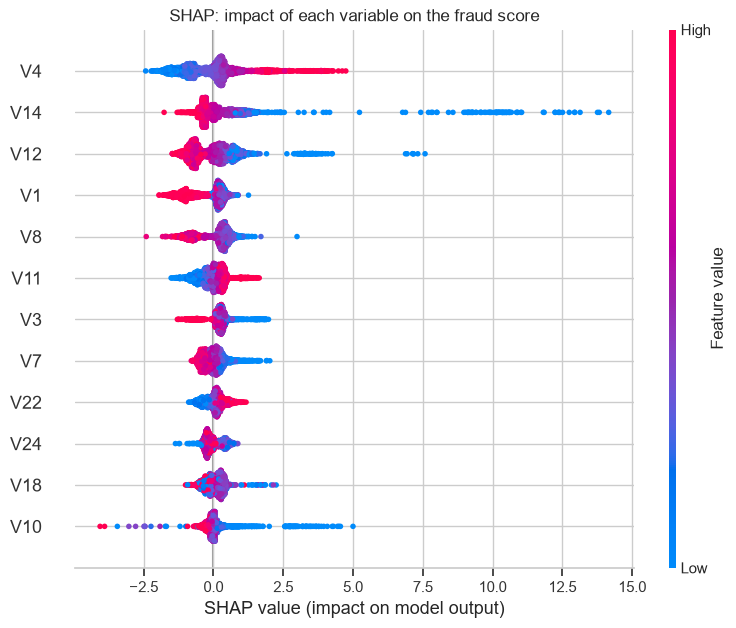

In [8]:
explicador = shap.TreeExplainer(gbm)
muestra = x_test.sample(3000, random_state=0)
muestra = pd.concat([muestra, x_test[y_test == 1]]).drop_duplicates()
valores = explicador.shap_values(muestra)
if isinstance(valores, list):
    valores = valores[1]
plt.figure()
shap.summary_plot(valores, muestra, show=False, max_display=12)
plt.title("SHAP: impact of each variable on the fraud score")
plt.savefig("figures/shap_summary.png", bbox_inches="tight")
plt.show()

In [9]:
importancia = pd.Series(np.abs(valores).mean(axis=0), index=muestra.columns).sort_values(ascending=False)
importancia.head(8).round(3)

V4     0.790
V14    0.721
V12    0.637
V1     0.544
V8     0.514
V11    0.330
V3     0.320
V7     0.280
dtype: float64

## Part 7. Is the score stable in time?

We compare the distribution of the score in the first and the second half of the test period with the PSI.

In [10]:
mitad = test["orden"].median()
a = p_gbm[test["orden"].values <= mitad]
b = p_gbm[test["orden"].values > mitad]
cortes = np.unique(np.quantile(a, np.linspace(0, 1, 11)))
cortes[0], cortes[-1] = -np.inf, np.inf
pa = np.histogram(a, cortes)[0] / len(a)
pb = np.histogram(b, cortes)[0] / len(b)
psi = np.sum((pa - pb) * np.log(np.clip(pa, 1e-6, None) / np.clip(pb, 1e-6, None)))
print("PSI between the two halves of the test period:", round(psi, 4))

PSI between the two halves of the test period: 0.007


## Conclusions

- With 0.17% of fraud, the ROC-AUC looks excellent for both models (0.98) but the average precision shows the real difference: 0.80 for LightGBM against 0.75 for the logistic regression.
- In the test period the frauds sum around 14.600 EUR. With the model and a threshold of 0.02 the total cost (fraud not detected + review of 111 alerts) falls to around 3.400 EUR, 77% less, catching 84 of 108 frauds.
- Here the optimal threshold is far from 0.5 but the cost is similar (3.556 EUR at 0.5), because the scores of frauds and normal transactions are very separated. In a real project the threshold should be chosen in a validation period and not in the test period, as we did here to keep the example short.
- SHAP shows which variables push each alert (V4, V14 and V12 are the most important), so the model can be explained to the fraud analysts and to model validation. The score is stable inside the test period (PSI 0.007).